# Exploratory Data Analysis - GoEmotions Dataset

This notebook performs exploratory data analysis on the balanced GoEmotions dataset for binary sentiment classification.

**Objectives:**
- Verify data quality and balance (500 positive / 500 negative)
- Analyze text characteristics (length, distribution)
- Generate visualizations for the final report

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import sys
import os

sys.path.append(os.path.join(os.getcwd(), '..'))

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print("Libraries imported successfully")

Libraries imported successfully


## 1. Load Dataset

In [5]:
df = pd.read_csv('../data/processed/balanced_dataset.csv')

print(f"Dataset shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nFirst 5 rows:")
df.head()

Dataset shape: (1000, 7)

Columns: ['comment_text', 'emotion_ids', 'id', 'sentiment', 'cleaned_text', 'tokens', 'text_length']

First 5 rows:


,comment_text,emotion_ids,id,sentiment,cleaned_text,tokens,text_length
0,Just do the steps and stop complaining.,[3],eeptnqi,negative,just do the steps and stop complaining,"['steps', 'stop', 'complaining']",3
1,How could I not? These actors...I love them. T...,[18],ed28sbm,negative,how could i not these actorsi love them their ...,"['could', 'actorsi', 'love', 'faces', 'give', ...",7
2,[NAME] is a good basketball player,[0],ef2nn9m,negative,name is a good basketball player,"['name', 'good', 'basketball', 'player']",4
3,I love you ❤️,[18],edobddo,negative,i love you,['love'],1
4,Fuuuuuck. That’s the worst I’ve seen.,[2],eempufb,positive,fuuuuuck thats the worst ive seen,"['fuuuuuck', 'thats', 'worst', 'ive', 'seen']",5


In [6]:
print("Dataset Info:")
print("=" * 80)
df.info()
print("\n" + "=" * 80)
print(f"\nMissing values per column:")
print(df.isnull().sum())
print(f"\nTotal missing values: {df.isnull().sum().sum()}")

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   comment_text  1000 non-null   str  
 1   emotion_ids   1000 non-null   str  
 2   id            1000 non-null   str  
 3   sentiment     1000 non-null   str  
 4   cleaned_text  1000 non-null   str  
 5   tokens        1000 non-null   str  
 6   text_length   1000 non-null   int64
dtypes: int64(1), str(6)
memory usage: 54.8 KB


Missing values per column:
comment_text    0
emotion_ids     0
id              0
sentiment       0
cleaned_text    0
tokens          0
text_length     0
dtype: int64

Total missing values: 0


## 2. Class Balance Analysis

Verify that the dataset is perfectly balanced (500 positive / 500 negative).

In [7]:
class_counts = df['sentiment'].value_counts()
print("Class Distribution:")
print(class_counts)
print(f"\nPercentage:")
print((class_counts / len(df) * 100).round(2))

Class Distribution:
sentiment
negative    500
positive    500
Name: count, dtype: int64

Percentage:
sentiment
negative    50.0
positive    50.0
Name: count, dtype: float64


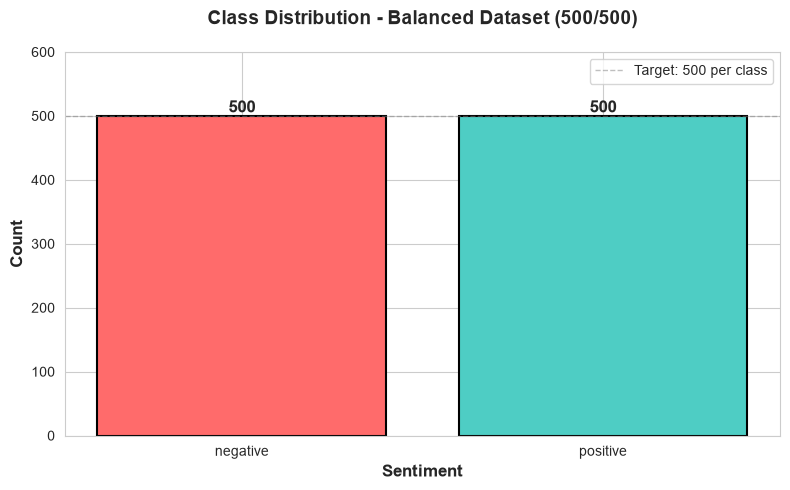


Figure saved to outputs/figures/class_distribution.png


In [8]:
fig, ax = plt.subplots(figsize=(8, 5))

colors = ['#FF6B6B', '#4ECDC4']
bars = ax.bar(class_counts.index, class_counts.values, color=colors, edgecolor='black', linewidth=1.5)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(height)}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_xlabel('Sentiment', fontsize=12, fontweight='bold')
ax.set_ylabel('Count', fontsize=12, fontweight='bold')
ax.set_title('Class Distribution - Balanced Dataset (500/500)', fontsize=14, fontweight='bold', pad=20)
ax.set_ylim(0, 600)
ax.axhline(y=500, color='gray', linestyle='--', linewidth=1, alpha=0.5, label='Target: 500 per class')
ax.legend()

plt.tight_layout()
plt.savefig('../outputs/figures/class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nFigure saved to outputs/figures/class_distribution.png")

## 3. Text Length Analysis

Analyze the distribution of text lengths (in words) for both classes.

In [9]:
df['text_length'] = df['cleaned_text'].apply(lambda x: len(str(x).split()))

print("Text Length Statistics (in words):")
print("=" * 80)
print(df['text_length'].describe())
print("\n" + "=" * 80)
print("\nBy Sentiment:")
print(df.groupby('sentiment')['text_length'].describe())

Text Length Statistics (in words):
count    1000.000000
mean       12.931000
std         6.711728
min         1.000000
25%         7.000000
50%        13.000000
75%        18.000000
max        29.000000
Name: text_length, dtype: float64


By Sentiment:
           count    mean       std  min  25%   50%    75%   max
sentiment                                                      
negative   500.0  13.656  6.469418  1.0  8.0  14.0  18.25  29.0
positive   500.0  12.206  6.875909  1.0  6.0  12.0  17.00  29.0


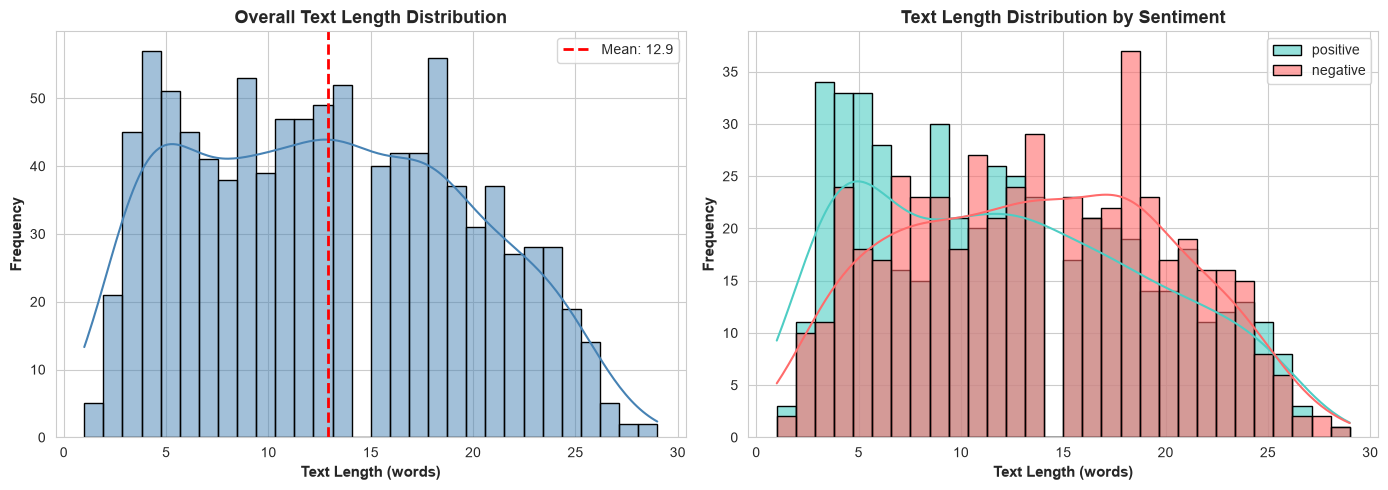


 Figure saved to outputs/figures/text_length_distribution.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['text_length'], bins=30, kde=True, ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_xlabel('Text Length (words)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Frequency', fontsize=11, fontweight='bold')
axes[0].set_title('Overall Text Length Distribution', fontsize=13, fontweight='bold')
axes[0].axvline(df['text_length'].mean(), color='red', linestyle='--', linewidth=2, label=f"Mean: {df['text_length'].mean():.1f}")
axes[0].legend()

for sentiment, color in [('positive', '#4ECDC4'), ('negative', '#FF6B6B')]:
    subset = df[df['sentiment'] == sentiment]['text_length']
    sns.histplot(subset, bins=30, kde=True, ax=axes[1], color=color, label=sentiment, alpha=0.6, edgecolor='black')

axes[1].set_xlabel('Text Length (words)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Frequency', fontsize=11, fontweight='bold')
axes[1].set_title('Text Length Distribution by Sentiment', fontsize=13, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig('../outputs/figures/text_length_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n Figure saved to outputs/figures/text_length_distribution.png")

## 4. Sample Texts

Examine sample texts from each class to understand the data characteristics.

In [11]:
print("Sample POSITIVE comments:")
print("=" * 80)
positive_samples = df[df['sentiment'] == 'positive']['cleaned_text'].sample(5, random_state=42)
for idx, text in positive_samples.items():
    print(f"{idx}: {text}\n")

print("\n" + "=" * 80)
print("\nSample NEGATIVE comments:")
print("=" * 80)
negative_samples = df[df['sentiment'] == 'negative']['cleaned_text'].sample(5, random_state=42)
for idx, text in negative_samples.items():
    print(f"{idx}: {text}\n")

Sample POSITIVE comments:
707: what media is this scene from

156: this guy fucking gets it

728: same ugh

315: how is this the epitome of slavery nobody is forcing you to do this stop being dramatic

223: sometimes i just go on the youtube video for any song older than like 20 years and these comments never disappoint



Sample NEGATIVE comments:
741: to be fair the world especially politics has been kind of a shit show since 2016

133: all this theft should be reported to the school so it can go on his spermanent record

757: a hell of a player when he was at grimsby hope he can pick up some minutes and goals again

309: i love that channel

201: none of the movies deserve it and honestly the oscars are a sham at this point



## 5. Summary Statistics

Key findings from the EDA:
- Dataset is perfectly balanced (500 positive / 500 negative)
- No missing values
- Text lengths vary from [min] to [max] words, with a mean of [mean] words
- Both classes show similar text length distributions